In [23]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')
%matplotlib inline
sns.set_style("whitegrid")

In [24]:
df=pd.read_csv('student.csv')

In [25]:
lekage=[]
for x in ['G1','G2','G3']:
    if x in df.columns:
        lekage.append(x)


In [26]:
df=df.drop(columns=lekage)

In [27]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,course,passed
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,no,4,3,4,1,1,3,6,math,0
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,no,5,3,3,1,1,3,4,math,0
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,no,4,3,2,2,3,3,10,math,1
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,3,2,2,1,1,5,2,math,1
4,GP,F,16,U,GT3,T,3,3,other,other,...,no,4,3,2,1,2,5,4,math,1


In [28]:
df.describe(include='all')

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,course,passed
count,1044,1044,1044.000000,1044,1044,1044,1044.000000,1044.000000,1044,1044,...,1044,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044,1044.000000
unique,2,2,NaN,2,2,2,NaN,NaN,5,5,...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN
top,GP,F,NaN,U,GT3,T,NaN,NaN,other,other,...,no,NaN,NaN,NaN,NaN,NaN,NaN,NaN,portuguese,NaN
freq,772,591,NaN,759,738,923,NaN,NaN,399,584,...,673,NaN,NaN,NaN,NaN,NaN,NaN,NaN,649,NaN
mean,NaN,NaN,16.726054,NaN,NaN,NaN,2.603448,2.387931,NaN,NaN,...,NaN,3.935824,3.201149,3.156130,1.494253,2.284483,3.543103,4.434866,NaN,0.779693
std,NaN,NaN,1.239975,NaN,NaN,NaN,1.124907,1.099938,NaN,NaN,...,NaN,0.933401,1.031507,1.152575,0.911714,1.285105,1.424703,6.210017,NaN,0.414652
min,NaN,NaN,15.000000,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,...,NaN,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,NaN,0.000000
25%,NaN,NaN,16.000000,NaN,NaN,NaN,2.000000,1.000000,NaN,NaN,...,NaN,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,NaN,1.000000
50%,NaN,NaN,17.000000,NaN,NaN,NaN,3.000000,2.000000,NaN,NaN,...,NaN,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,NaN,1.000000
75%,NaN,NaN,18.000000,NaN,NaN,NaN,4.000000,3.000000,NaN,NaN,...,NaN,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,NaN,1.000000


In [29]:
df.duplicated().sum()

0

In [30]:
missing=df.isnull().sum()
missing_perc=(missing/len(df)*100).round(2)

In [31]:
missing_perc

school        0.0
sex           0.0
age           0.0
address       0.0
famsize       0.0
Pstatus       0.0
Medu          0.0
Fedu          0.0
Mjob          0.0
Fjob          0.0
reason        0.0
guardian      0.0
traveltime    0.0
studytime     0.0
failures      0.0
schoolsup     0.0
famsup        0.0
paid          0.0
activities    0.0
nursery       0.0
higher        0.0
internet      0.0
romantic      0.0
famrel        0.0
freetime      0.0
goout         0.0
Dalc          0.0
Walc          0.0
health        0.0
absences      0.0
course        0.0
passed        0.0
dtype: float64

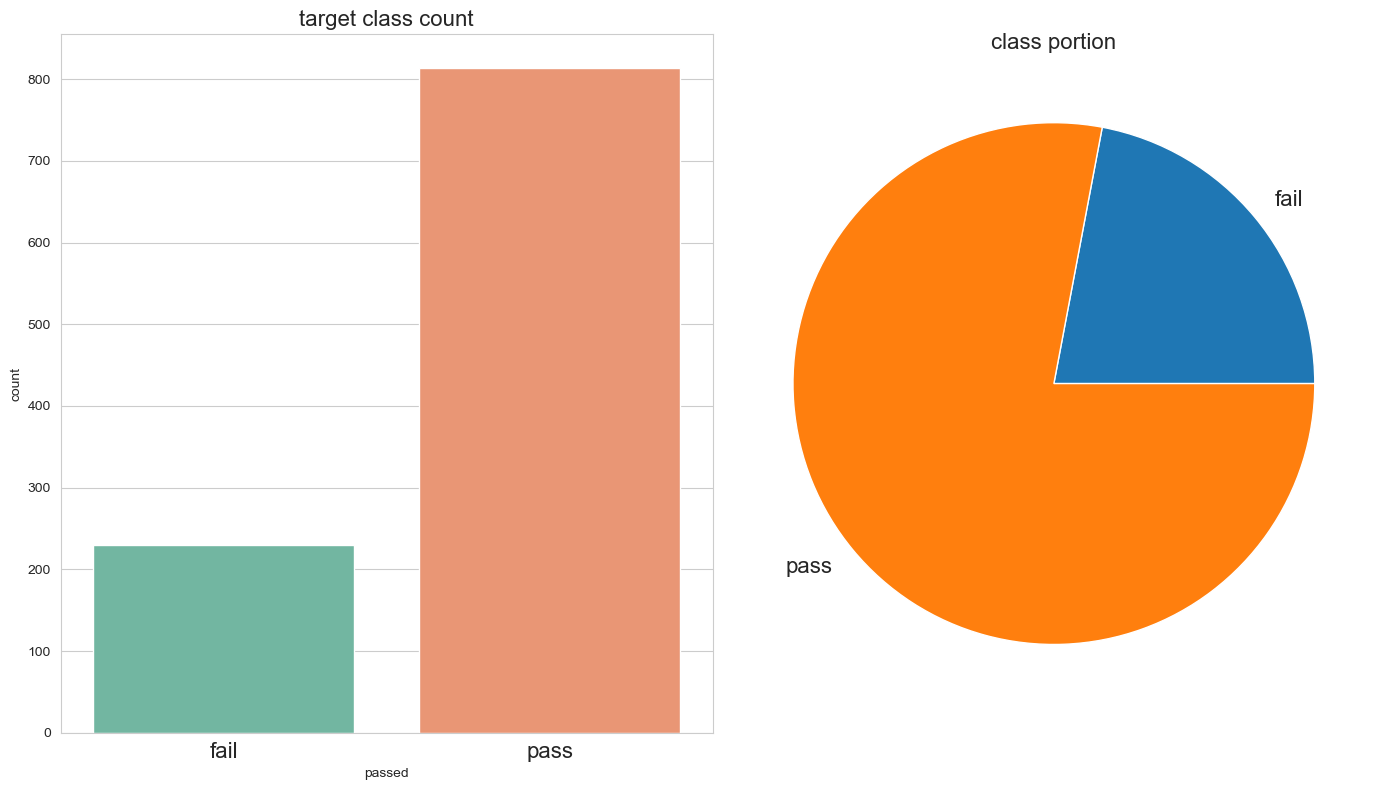

In [46]:
fig,axes= plt.subplots(1,2,figsize=(14,8))
target_count=df['passed'].value_counts().sort_index() #count pass and fail

sns.countplot(data=df, x='passed', ax=axes[0],palette='Set2')
axes[0].set_title('target class count' ,fontsize=16 )
axes[0].set_xticklabels(['fail','pass'],fontsize=16)
            

axes[1].pie(
    target_count,
    labels=['fail','pass'],
    textprops={'fontsize': 16}
)
axes[1].set_title('class portion',fontsize=16)
plt.tight_layout()

In [50]:
numeric_cols=df.select_dtypes(include=[np.number]).columns.tolist()
if 'passed' in numeric_cols:
    numeric_cols.remove('passed')

In [51]:
numeric_cols

['age',
 'Medu',
 'Fedu',
 'traveltime',
 'studytime',
 'failures',
 'famrel',
 'freetime',
 'goout',
 'Dalc',
 'Walc',
 'health',
 'absences']

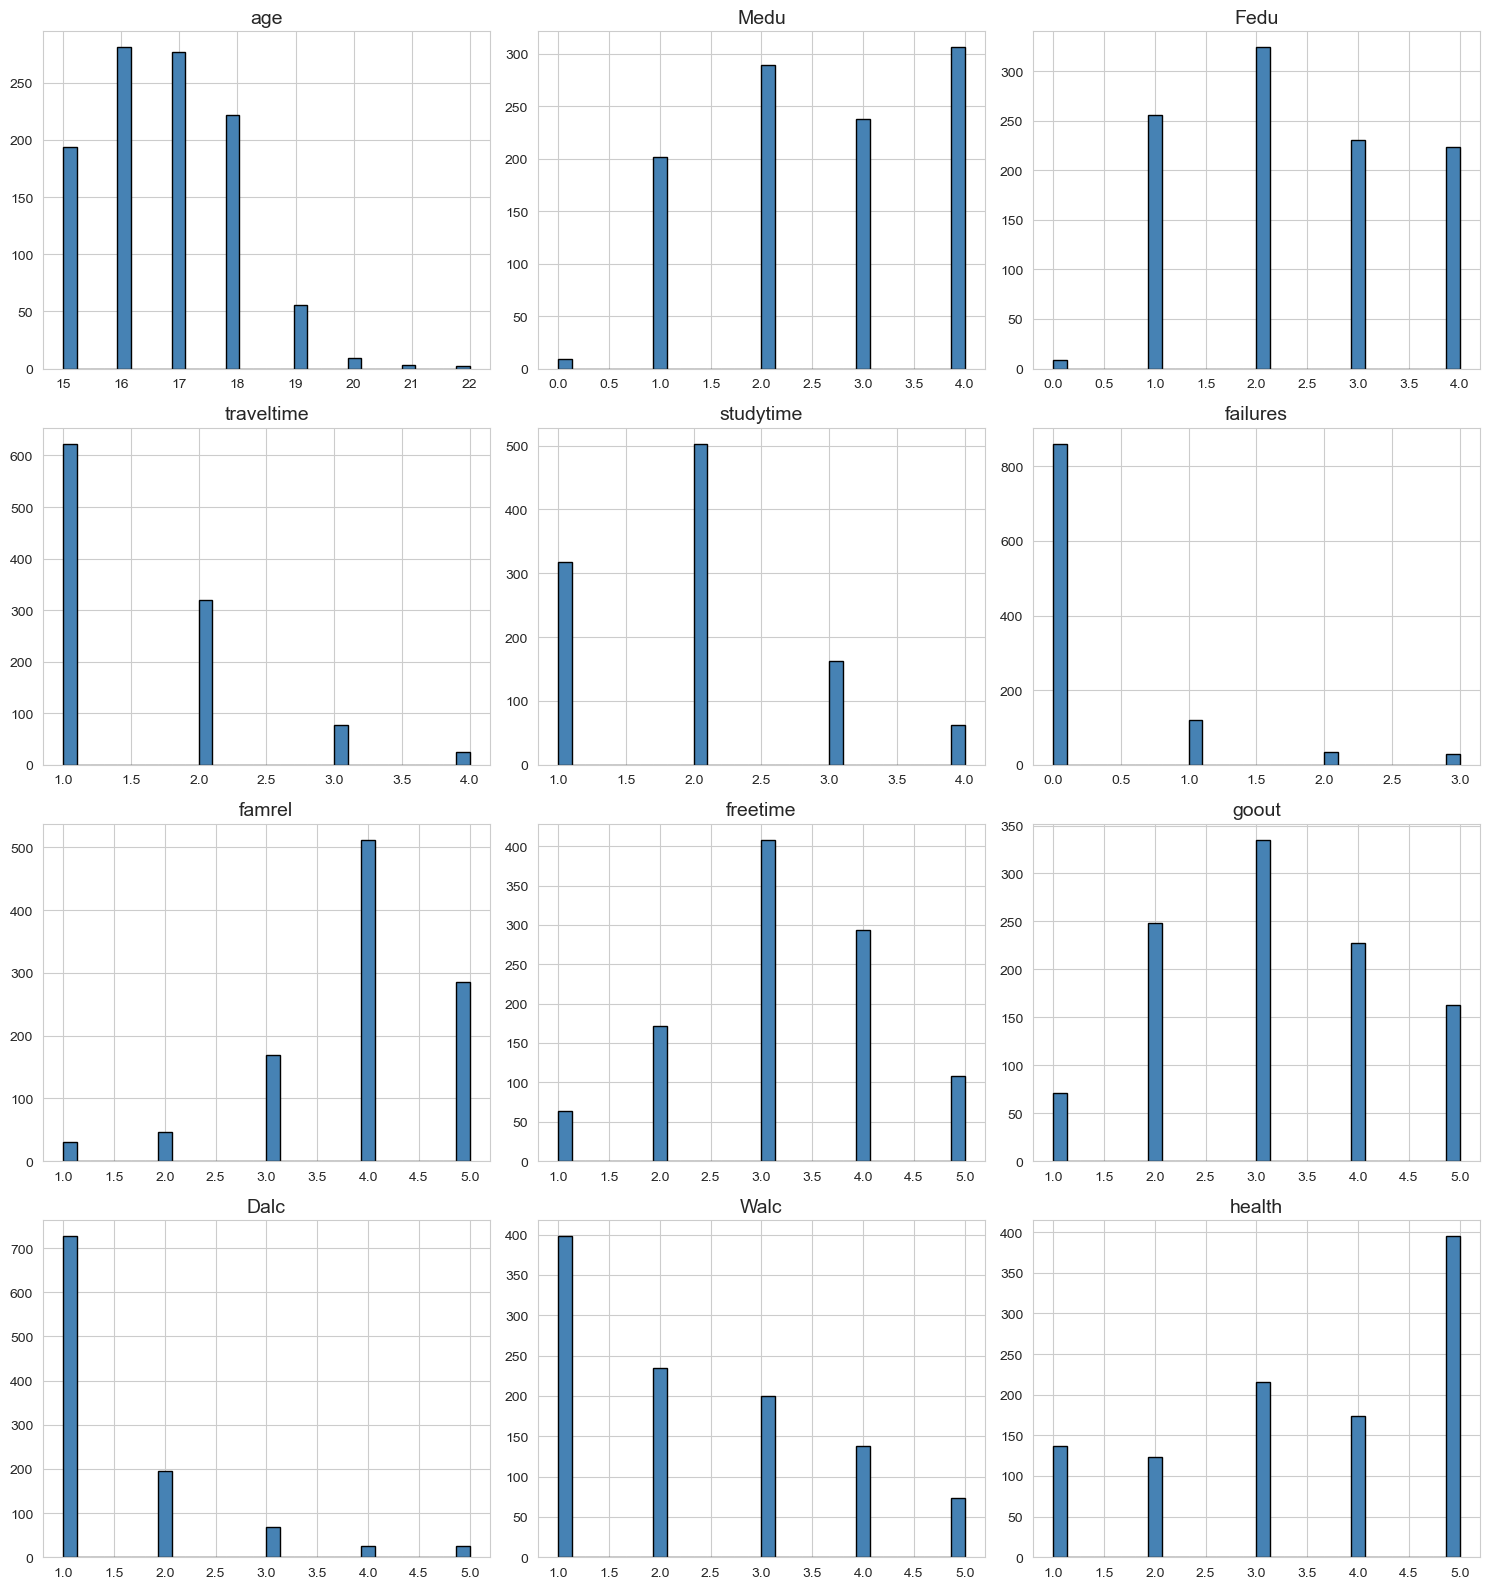

In [52]:
import math


n_show = min(len(numeric_cols), 12)


ncols = 3
nrows = math.ceil(n_show / ncols)

# Create the plots
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))


axes = np.array(axes).flatten()


for i in range(n_show):
    col = numeric_cols[i]

    df[col].hist(
        ax=axes[i],
        bins=30,
        color='steelblue',
        edgecolor='black'
    )

    axes[i].set_title(col, fontsize=14)


for j in range(n_show, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()